# Лабораторная работа № 4. Исследование случайного леса

**Цель работы** — исследовать случайный лес для классификации манёвров робота и регрессии загрузки CPU, оценить качество на обучающей и тестовой выборках и сравнить важность признаков.

Случайный лес объединяет предсказания решающих деревьев. Каждое дерево обучается на своей bootstrap-выборке: строки случайно выбираются из обучающего набора с возвращением, поэтому некоторые строки повторяются, а некоторые пропускаются. При каждом разбиении дерево рассматривает случайно выбранные признаки, если заданное число кандидатов меньше общего числа признаков. По умолчанию в sklearn для классификации берётся примерно квадратный корень из числа признаков, а для регрессии доступны все признаки. Классификатор усредняет вероятности классов от всех деревьев и выбирает класс с наибольшей вероятностью. Регрессор усредняет числовые прогнозы.

## 1. Подготовка данных

Загрузим прежние CSV. У робота используем 24 показания датчиков и цель `class`, у CPU — 21 признак и цель `usr`. Сохраним последовательные срезы из предыдущих работ и зазор 90 строк перед тестом робота.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

robot = pd.read_csv("data/wall_following_robot_24.csv")
cpu = pd.read_csv("data/cpu_act_44132.csv")

X_robot = robot.drop(columns="class")
y_robot = robot["class"]
X_cpu = cpu.drop(columns="usr")
y_cpu = cpu["usr"]

# Правая граница среза не включается.
robot_train = slice(0, 4274)
robot_test = slice(4364, 5456)
cpu_train = slice(0, 6553)
cpu_test = slice(6553, 8192)

assert len(robot) == robot_test.stop and len(cpu) == cpu_test.stop

X_robot_train, X_robot_test = X_robot.iloc[robot_train], X_robot.iloc[robot_test]
y_robot_train, y_robot_test = y_robot.iloc[robot_train], y_robot.iloc[robot_test]
X_cpu_train, X_cpu_test = X_cpu.iloc[cpu_train], X_cpu.iloc[cpu_test]
y_cpu_train, y_cpu_test = y_cpu.iloc[cpu_train], y_cpu.iloc[cpu_test]

print(f"Робот: {len(X_robot_train)} обучающих и {len(X_robot_test)} тестовых строк.")
print(f"CPU: {len(X_cpu_train)} обучающих и {len(X_cpu_test)} тестовых строк.")

Робот: 4274 обучающих и 1092 тестовых строк.
CPU: 6553 обучающих и 1639 тестовых строк.


## 2. Создание исходного бейзлайна и оценка качества

Обучим классификатор и регрессор со стандартными параметрами и `random_state=42`. Оставим стандартный режим `n_jobs=None`, при обычном запуске вычисления идут последовательно. Посчитаем метрики для обеих выборок.

In [2]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

robot_baseline = RandomForestClassifier(random_state=42)
cpu_baseline = RandomForestRegressor(random_state=42)
robot_baseline.fit(X_robot_train, y_robot_train)
cpu_baseline.fit(X_cpu_train, y_cpu_train)

y_robot_train_pred = robot_baseline.predict(X_robot_train)
y_robot_pred = robot_baseline.predict(X_robot_test)
y_cpu_train_pred = cpu_baseline.predict(X_cpu_train)
y_cpu_pred = cpu_baseline.predict(X_cpu_test)

samples = pd.Index(["Обучение", "Тест"], name="Выборка")
baseline_classification = pd.DataFrame([
    {"Accuracy": accuracy_score(actual, predicted),
     "F1-macro": f1_score(actual, predicted, average="macro")}
    for actual, predicted in [
        (y_robot_train, y_robot_train_pred), (y_robot_test, y_robot_pred),
    ]
], index=samples)

baseline_regression = pd.DataFrame([
    {"MAE, п. п.": mean_absolute_error(actual, predicted),
     "RMSE, п. п.": mean_squared_error(actual, predicted) ** 0.5,
     "R²": r2_score(actual, predicted)}
    for actual, predicted in [
        (y_cpu_train, y_cpu_train_pred), (y_cpu_test, y_cpu_pred),
    ]
], index=samples)

display(baseline_classification.round(4))
display(baseline_regression.round(4))

,Accuracy,F1-macro
Выборка,,
Обучение,1.0000,1.0000
Тест,0.9872,0.9863


,"MAE, п. п.","RMSE, п. п.",R²
Выборка,,,
Обучение,0.6285,0.9087,0.9976
Тест,1.8437,2.6762,0.9756


### Графики качества на тесте

Построим матрицу ошибок по манёврам робота и сопоставим фактические и предсказанные значения `usr`. Диагональ на графике регрессии соответствует точному прогнозу.

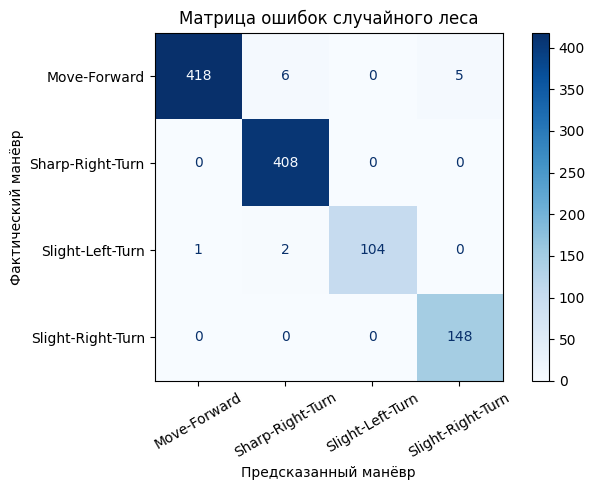

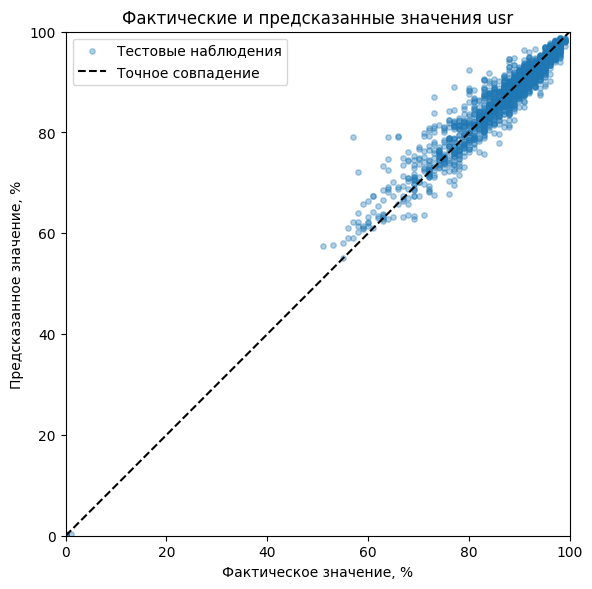

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_robot_test, y_robot_pred, labels=robot_baseline.classes_,
    cmap="Blues", values_format="d", xticks_rotation=30, ax=ax,
)
ax.set(title="Матрица ошибок случайного леса",
       xlabel="Предсказанный манёвр", ylabel="Фактический манёвр")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_cpu_test, y_cpu_pred, s=15, alpha=0.35, label="Тестовые наблюдения")
ax.plot([0, 100], [0, 100], "--", color="black", label="Точное совпадение")
ax.set(title="Фактические и предсказанные значения usr",
       xlabel="Фактическое значение, %", ylabel="Предсказанное значение, %",
       xlim=(0, 100), ylim=(0, 100), aspect="equal")
ax.legend()
fig.tight_layout()
plt.show()

### Важность признаков

Покажем десять признаков с наибольшей важностью для каждого леса. Важность отражает, насколько разбиения по этому признаку в среднем уменьшают неоднородность в деревьях. У коррелирующих признаков вклад может распределяться между ними.

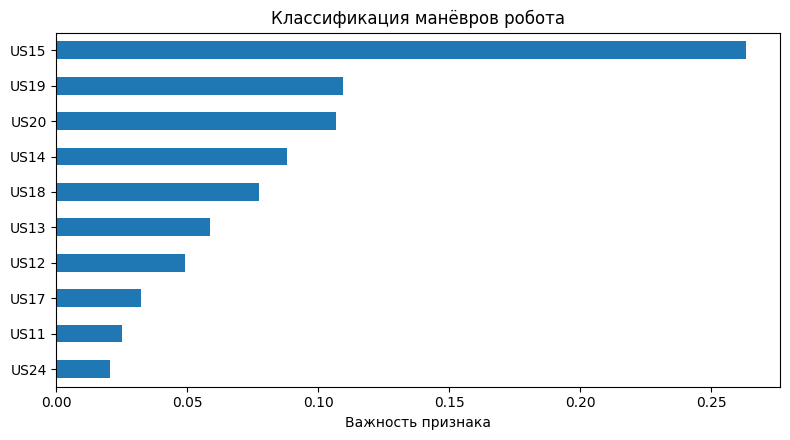

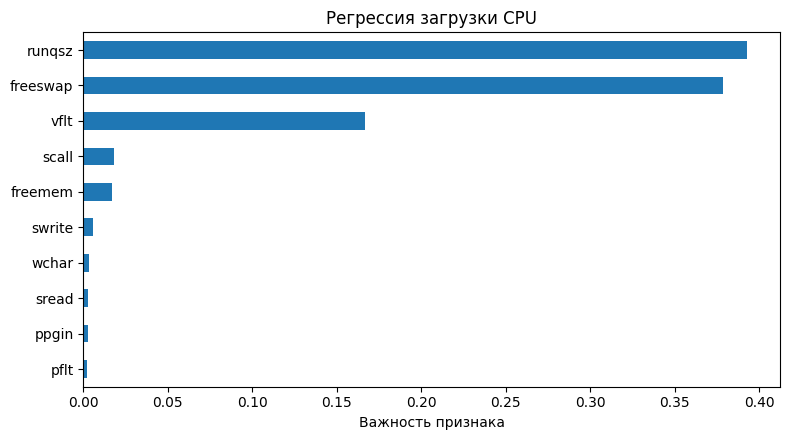

In [4]:
for title, model, features in [
    ("Классификация манёвров робота", robot_baseline, X_robot_train.columns),
    ("Регрессия загрузки CPU", cpu_baseline, X_cpu_train.columns),
]:
    importance = pd.Series(model.feature_importances_, index=features)
    top_features = importance.nlargest(10).sort_values()

    fig, ax = plt.subplots(figsize=(8, 4.5))
    top_features.plot.barh(ax=ax, color="tab:blue")
    ax.set(title=title, xlabel="Важность признака")
    fig.tight_layout()
    plt.show()

### Выводы

- **Классификация.** На обучении Accuracy и F1-macro равны 1,0000. На тесте Accuracy составила 0,9872, а F1-macro — 0,9863. На отложенных данных обе метрики немного снизились.
- **Регрессия.** MAE выросла с 0,6285 на обучении до 1,8437 п. п. на тесте, RMSE — с 0,9087 до 2,6762 п. п. Коэффициент R² снизился с 0,9976 до 0,9756.
- На тех же тестовых выборках лес со стандартными параметрами показал более высокий F1-macro, чем исходное решающее дерево из лабораторной № 3 (0,9863 против 0,9801), и меньшую MAE (1,8437 против 2,5790 п. п.).

## 3. Улучшение бейзлайна

1. **Число деревьев.** Увеличение `n_estimators` может улучшить качество за счёт усреднения большего числа прогнозов.
2. **Сложность деревьев.** Ограничение `max_depth` или увеличение `min_samples_leaf` может уменьшить переобучение. Слишком сильное ограничение может ухудшить качество.
3. **Выбор признаков.** Уменьшение `max_features` может повысить разнообразие деревьев и улучшить качество леса, хотя отдельным деревьям будет доступно меньше признаков при разбиении.

Для каждой задачи проверим 15 случайных комбинаций на трёх последовательных фолдах обучающей выборки. Для робота оставим зазор 90 строк. Сравним варианты по среднему F1-macro для классификации и MAE для регрессии. Включим стандартную конфигурацию в финальное сравнение на тех же фолдах и при равенстве средних оценок оставим её. Для MAE используем отрицательную оценку при поиске и меняем знак при выводе. Поиск и обучение лесов выполняем с `n_jobs=1`.

In [5]:
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_val_score

forest_grid = {
    "n_estimators": [30, 50, 100],
    "max_depth": [5, 10, 15, None],
    "min_samples_leaf": [1, 3, 5],
    "max_features": ["sqrt", 0.5, 1.0],
}

robot_folds = list(TimeSeriesSplit(n_splits=3, gap=90).split(X_robot_train))
cpu_folds = list(TimeSeriesSplit(n_splits=3).split(X_cpu_train))
robot_search = RandomizedSearchCV(
    clone(robot_baseline).set_params(n_jobs=1), forest_grid, n_iter=15,
    scoring="f1_macro", cv=robot_folds, random_state=42, n_jobs=1, refit=False,
    error_score="raise",
)
cpu_search = RandomizedSearchCV(
    clone(cpu_baseline).set_params(n_jobs=1), forest_grid, n_iter=15,
    scoring="neg_mean_absolute_error", cv=cpu_folds, random_state=42, n_jobs=1, refit=False,
    error_score="raise",
)

robot_search.fit(X_robot_train, y_robot_train)
cpu_search.fit(X_cpu_train, y_cpu_train)

robot_standard_scores = cross_val_score(
    robot_search.estimator, X_robot_train, y_robot_train,
    cv=robot_folds, scoring="f1_macro", n_jobs=1, error_score="raise",
)
cpu_standard_scores = cross_val_score(
    cpu_search.estimator, X_cpu_train, y_cpu_train,
    cv=cpu_folds, scoring="neg_mean_absolute_error", n_jobs=1, error_score="raise",
)

best_forest_params = []
for search, standard_scores in [
    (robot_search, robot_standard_scores), (cpu_search, cpu_standard_scores),
]:
    params = {name: search.estimator.get_params()[name] for name in forest_grid}
    if search.best_score_ > standard_scores.mean():
        params.update(search.best_params_)
    best_forest_params.append(dict(params, random_state=42))
best_robot_forest_params, best_cpu_forest_params = best_forest_params

print("Робот:", best_robot_forest_params)
print("CPU:", best_cpu_forest_params)

Робот: {'n_estimators': 100, 'max_depth': 15, 'min_samples_leaf': 3, 'max_features': 1.0, 'random_state': 42}
CPU: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 3, 'max_features': 0.5, 'random_state': 42}


### Проверенные комбинации

Выведем результаты 15 испытаний и стандартной конфигурации по каждому фолду, а также среднее и стандартное отклонение. Для регрессии меньшая MAE соответствует лучшему результату.

In [6]:
cv_tables = []
for title, search, standard_scores, metric, sign in [
    ("Робот", robot_search, robot_standard_scores, "F1-macro", 1),
    ("CPU", cpu_search, cpu_standard_scores, "MAE, п. п.", -1),
]:
    results = search.cv_results_
    rows = []
    for i, params in enumerate(results["params"]):
        scores = [results[f"split{fold}_test_score"][i] for fold in range(3)]
        rows.append({"Вариант": f"Поиск {i + 1}", **params,
                     **{f"Фолд {j}": sign * score for j, score in enumerate(scores, 1)},
                     metric: sign * results["mean_test_score"][i],
                     "Ст. откл.": results["std_test_score"][i]})
    standard_params = {name: search.estimator.get_params()[name] for name in forest_grid}
    rows.append({"Вариант": "Стандартный", **standard_params,
                 **{f"Фолд {j}": sign * score for j, score in enumerate(standard_scores, 1)},
                 metric: sign * standard_scores.mean(), "Ст. откл.": standard_scores.std()})
    table = pd.DataFrame(rows).set_index("Вариант").sort_values(metric, ascending=(sign == -1))
    table["max_depth"] = [str(int(value)) if pd.notna(value) else "None" for value in table["max_depth"]]
    cv_tables.append(table)
    print(title)
    display(table.round(4))

Робот


,n_estimators,min_samples_leaf,max_features,max_depth,Фолд 1,Фолд 2,Фолд 3,F1-macro,Ст. откл.
Вариант,,,,,,,,,
Поиск 1,100,3,1.0,15,0.9176,0.9724,0.9801,0.9567,0.0278
Поиск 9,100,3,0.5,None,0.9050,0.9631,0.9976,0.9552,0.0382
Поиск 12,50,5,1.0,15,0.9095,0.9661,0.9837,0.9531,0.0317
Поиск 14,100,5,1.0,15,0.9156,0.9562,0.9837,0.9518,0.0279
Поиск 6,50,3,0.5,15,0.8871,0.9671,0.9976,0.9506,0.0466
Поиск 11,30,1,sqrt,None,0.8954,0.9674,0.9802,0.9477,0.0374
Поиск 8,30,1,1.0,10,0.9289,0.9263,0.9801,0.9451,0.0248
Поиск 5,100,5,sqrt,15,0.9161,0.9523,0.9667,0.9450,0.0213
Стандартный,100,1,sqrt,None,0.8814,0.9630,0.9796,0.9413,0.0429


CPU


,n_estimators,min_samples_leaf,max_features,max_depth,Фолд 1,Фолд 2,Фолд 3,"MAE, п. п.",Ст. откл.
Вариант,,,,,,,,,
Поиск 9,100,3,0.5,None,1.8288,1.7904,1.6827,1.7673,0.0619
Стандартный,100,1,1.0,None,1.8180,1.8001,1.6946,1.7709,0.0544
Поиск 1,100,3,1.0,15,1.8323,1.8119,1.6967,1.7803,0.0597
Поиск 6,50,3,0.5,15,1.8283,1.8109,1.7022,1.7805,0.0558
Поиск 14,100,5,1.0,15,1.8675,1.8284,1.7093,1.8017,0.0673
Поиск 12,50,5,1.0,15,1.8805,1.8466,1.7103,1.8125,0.0736
Поиск 8,30,1,1.0,10,1.8584,1.8845,1.7817,1.8415,0.0436
Поиск 4,100,1,sqrt,None,1.9790,1.8756,1.7553,1.8700,0.0914
Поиск 11,30,1,sqrt,None,1.9986,1.9285,1.7723,1.8998,0.0946


### Проверка гипотез

Возьмём пары вариантов, в которых отличается ровно один параметр. Переходы идут от меньшего числа деревьев, глубины, размера листа или доли признаков к большему. Глубина `None` означает отсутствие ограничения. Разность рассчитана как метрика второго варианта минус метрика первого.

In [7]:
for title, table, metric in [
    ("Робот", cv_tables[0], "F1-macro"), ("CPU", cv_tables[1], "MAE, п. п."),
]:
    rows = []
    for param in forest_grid:
        others = [name for name in forest_grid if name != param]
        order = forest_grid[param] if param != "max_depth" else ["5", "10", "15", "None"]
        for _, group in table.groupby(others, sort=False):
            group = group.drop_duplicates(subset=param)
            values = group.set_index(param)
            for i, first in enumerate(order):
                for second in order[i + 1:]:
                    if first in values.index and second in values.index:
                        names = group.reset_index().set_index(param)["Вариант"]
                        before, after = values.loc[first, metric], values.loc[second, metric]
                        rows.append({
                            "Параметр": param, "Переход": f"{first} → {second}",
                            "Первый вариант": names.loc[first], "Второй вариант": names.loc[second],
                            "До": before, "После": after, "Разность": after - before,
                        })
    print(f"{title} — {metric}")
    display(pd.DataFrame(rows).round(4))

Робот — F1-macro


,Параметр,Переход,Первый вариант,Второй вариант,До,После,Разность
0,n_estimators,50 → 100,Поиск 12,Поиск 14,0.9531,0.9518,-0.0012
1,n_estimators,30 → 100,Поиск 11,Стандартный,0.9477,0.9413,-0.0063
2,n_estimators,50 → 100,Поиск 2,Поиск 10,0.9115,0.9094,-0.0021
3,max_depth,5 → None,Поиск 13,Поиск 11,0.8251,0.9477,0.1225
4,max_depth,5 → 10,Поиск 15,Поиск 8,0.9142,0.9451,0.0309
5,min_samples_leaf,3 → 5,Поиск 1,Поиск 14,0.9567,0.9518,-0.0049
6,max_features,sqrt → 1.0,Поиск 5,Поиск 14,0.9450,0.9518,0.0068
7,max_features,sqrt → 1.0,Поиск 13,Поиск 15,0.8251,0.9142,0.0891


CPU — MAE, п. п.


,Параметр,Переход,Первый вариант,Второй вариант,До,После,Разность
0,n_estimators,50 → 100,Поиск 12,Поиск 14,1.8125,1.8017,-0.0107
1,n_estimators,30 → 100,Поиск 11,Поиск 4,1.8998,1.8700,-0.0299
2,n_estimators,50 → 100,Поиск 2,Поиск 10,2.2935,2.2810,-0.0125
3,max_depth,5 → 10,Поиск 15,Поиск 8,2.3670,1.8415,-0.5255
4,max_depth,5 → None,Поиск 13,Поиск 11,2.5310,1.8998,-0.6312
5,min_samples_leaf,3 → 5,Поиск 1,Поиск 14,1.7803,1.8017,0.0214
6,max_features,sqrt → 1.0,Поиск 4,Стандартный,1.8700,1.7709,-0.0990
7,max_features,sqrt → 1.0,Поиск 5,Поиск 14,2.0172,1.8017,-0.2155
8,max_features,sqrt → 1.0,Поиск 13,Поиск 15,2.5310,2.3670,-0.1640


### Сравнение на обучении и тесте

Обучим выбранные леса на всей обучающей выборке. Сравним все метрики с бейзлайном на прежних обучающих и тестовых срезах.

In [8]:
robot_improved = RandomForestClassifier(**best_robot_forest_params, n_jobs=1)
cpu_improved = RandomForestRegressor(**best_cpu_forest_params, n_jobs=1)
robot_improved.fit(X_robot_train, y_robot_train)
cpu_improved.fit(X_cpu_train, y_cpu_train)

improved_classification = pd.DataFrame([
    {"Accuracy": accuracy_score(actual, predicted),
     "F1-macro": f1_score(actual, predicted, average="macro")}
    for actual, predicted in [
        (y_robot_train, robot_improved.predict(X_robot_train)),
        (y_robot_test, robot_improved.predict(X_robot_test)),
    ]
], index=baseline_classification.index)

improved_regression = pd.DataFrame([
    {"MAE, п. п.": mean_absolute_error(actual, predicted),
     "RMSE, п. п.": mean_squared_error(actual, predicted) ** 0.5,
     "R²": r2_score(actual, predicted)}
    for actual, predicted in [
        (y_cpu_train, cpu_improved.predict(X_cpu_train)),
        (y_cpu_test, cpu_improved.predict(X_cpu_test)),
    ]
], index=baseline_regression.index)

versions = ["Бейзлайн", "После подбора"]
display(pd.concat([baseline_classification, improved_classification], axis=1, keys=versions).round(4))
display(pd.concat([baseline_regression, improved_regression], axis=1, keys=versions).round(4))

Бейзлайн          После подбора         
         Accuracy F1-macro      Accuracy F1-macro
Выборка                                          
Обучение   1.0000   1.0000        0.9993   0.9993
Тест       0.9872   0.9863        0.9899   0.9885

Бейзлайн                     После подбора                    
         MAE, п. п. RMSE, п. п.      R²    MAE, п. п. RMSE, п. п.      R²
Выборка                                                                  
Обучение     0.6285      0.9087  0.9976        0.8785      1.2932  0.9952
Тест         1.8437      2.6762  0.9756        1.8485      2.6995  0.9752

### Сравнительные графики

Покажем все метрики для исходных и выбранных лесов на обучении и тесте.

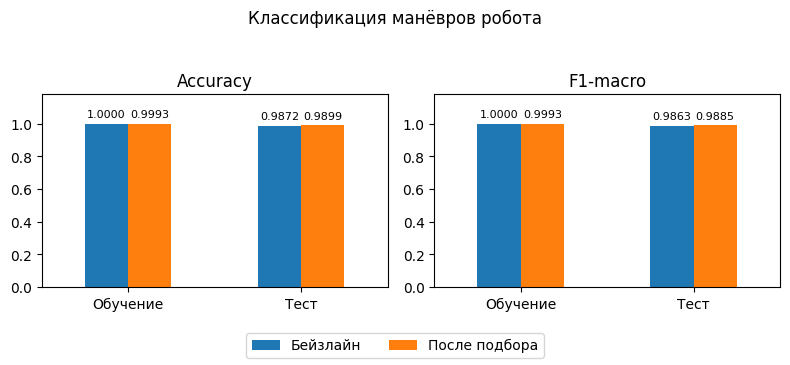

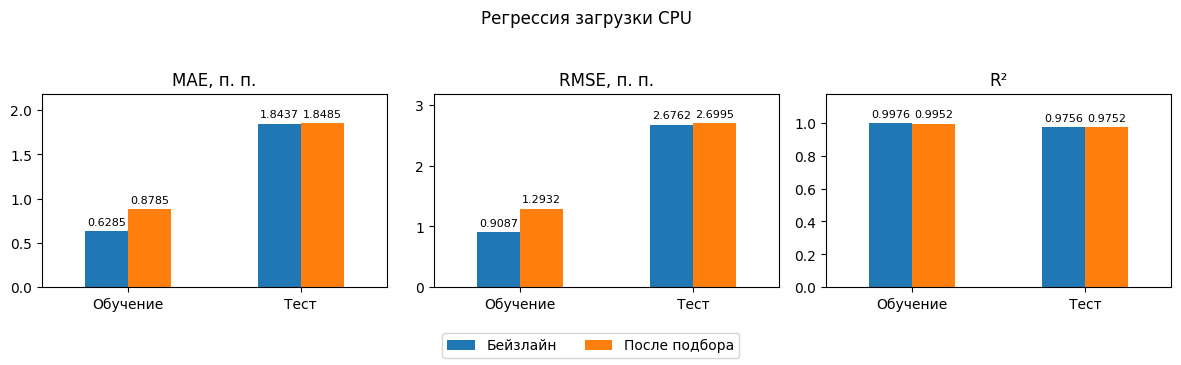

In [9]:
for title, baseline, improved in [
    ("Классификация манёвров робота", baseline_classification, improved_classification),
    ("Регрессия загрузки CPU", baseline_regression, improved_regression),
]:
    fig, axes = plt.subplots(1, len(baseline.columns), figsize=(4 * len(baseline.columns), 3.6))
    for ax, metric in zip(axes, baseline.columns):
        comparison = pd.DataFrame({versions[0]: baseline[metric], versions[1]: improved[metric]})
        comparison.plot.bar(ax=ax, rot=0, title=metric, legend=False, xlabel="")
        for bars in ax.containers:
            ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)
        ax.margins(y=0.18)
    fig.suptitle(title)
    fig.legend(axes[0].containers, versions, loc="lower center", ncol=2)
    fig.tight_layout(rect=(0, 0.10, 1, 0.94))
    plt.show()

### Выводы

1. **Число деревьев.** Увеличение числа деревьев до 100 снизило валидационную MAE во всех трёх сопоставимых парах для CPU. В трёх парах для робота F1-macro при этом немного снизился. Результат зависит от задачи и проверенных настроек.
2. **Сложность деревьев.** При глубине 5 валидация показала худшее качество, чем при глубине 10 или без ограничения, в обеих задачах. В единственной сопоставимой паре для размера листа переход с 3 до 5 ухудшил обе метрики. По этим парам можно судить о качестве на валидации. Чтобы оценить влияние отдельного ограничения на переобучение, потребовалось бы также сравнить разрывы между обучением и валидацией на фолдах.
3. **Выбор признаков.** Во всех сопоставимых парах переход с `"sqrt"` на `1.0` улучшил валидационную метрику. Для `0.5` сопоставимых пар не оказалось. Лучшая конфигурация для CPU использует `0.5`, но её преимущество относится ко всей комбинации параметров.

- **Классификация.** Средний F1-macro на кросс-валидации вырос с 0,9413 до 0,9567. На тесте F1-macro вырос с 0,9863 до 0,9885, а Accuracy — с 0,9872 до 0,9899.
- **Регрессия.** Средняя MAE на кросс-валидации снизилась с 1,7709 до 1,7673 п. п. На тесте улучшения нет. MAE выросла с 1,8437 до 1,8485 п. п., RMSE — с 2,6762 до 2,6995 п. п., а R² снизился с 0,9756 до 0,9752.

## 4. Самостоятельная реализация алгоритма

Возьмём собственные деревья из лабораторной № 3. Сохраним рекурсивное построение, критерии Джини и квадратичной ошибки, сортировку и накопительные суммы при поиске порога. В каждом узле перемешаем признаки и проверим первые `max_features`. Если среди них нет допустимого разбиения, продолжим перебор до первого допустимого признака или до конца списка. В листе классификатора сохраним доли классов, в листе регрессора — среднее значение цели.

In [10]:
import numpy as np


class _SimpleTree:
    _classification = False

    def __init__(self, max_depth=None, min_samples_leaf=1, min_samples_split=2,
                 random_state=None, max_features=1.0):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split
        self.random_state = random_state
        self.max_features = max_features

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if X.ndim != 2 or not X.size or y.shape != (len(X),):
            raise ValueError("Нужны непустая матрица признаков и одномерная цель.")
        if not np.isfinite(X).all():
            raise ValueError("Признаки должны быть конечными числами.")
        for name, value, minimum in [
            ("max_depth", self.max_depth, 1),
            ("min_samples_leaf", self.min_samples_leaf, 1),
            ("min_samples_split", self.min_samples_split, 2),
        ]:
            if name == "max_depth" and value is None:
                continue
            if not isinstance(value, (int, np.integer)) or value < minimum:
                raise ValueError(f"{name} должен быть целым числом от {minimum}.")

        if self._classification:
            self.classes_, y = np.unique(y, return_inverse=True)
        else:
            y = y.astype(float)
            if not np.isfinite(y).all():
                raise ValueError("Цель регрессии должна содержать конечные числа.")

        self.n_features_in_ = X.shape[1]
        if self.max_features == "sqrt":
            self.max_features_ = max(1, int(np.sqrt(self.n_features_in_)))
        elif self.max_features is None:
            self.max_features_ = self.n_features_in_
        elif isinstance(self.max_features, (int, np.integer)) and 1 <= self.max_features <= self.n_features_in_:
            self.max_features_ = self.max_features
        elif isinstance(self.max_features, (float, np.floating)) and 0 < self.max_features <= 1:
            self.max_features_ = max(1, int(self.max_features * self.n_features_in_))
        else:
            raise ValueError("max_features должен быть 'sqrt', None, допустимым числом или долей признаков.")
        self.depth_ = 0
        self.n_leaves_ = 0
        self._rng = np.random.default_rng(self.random_state)
        self.tree_ = self._grow(X, y, depth=0)
        return self

    def _best_split(self, X, y):
        n = len(y)
        best_cost = np.inf
        best_split = None
        if self._classification:
            targets = y[:, None] == np.arange(len(self.classes_))
        else:
            # Центрирование снижает потерю точности при вычитании близких сумм.
            targets = y - y.mean()

        for i_feature, feature in enumerate(self._rng.permutation(X.shape[1])):
            if i_feature >= self.max_features_ and best_split is not None:
                break
            order = np.argsort(X[:, feature], kind="stable")
            values = X[order, feature]
            cuts = np.flatnonzero(values[:-1] < values[1:]) + 1
            cuts = cuts[(cuts >= self.min_samples_leaf) & (n - cuts >= self.min_samples_leaf)]
            if cuts.size == 0:
                continue

            sorted_targets = targets[order]
            prefix = np.cumsum(sorted_targets, axis=0)
            left = prefix[cuts - 1]
            right = prefix[-1] - left
            if self._classification:
                # Взвешенный Джини с общим множителем n.
                costs = n - (left ** 2).sum(axis=1) / cuts - (right ** 2).sum(axis=1) / (n - cuts)
            else:
                squared_prefix = np.cumsum(sorted_targets ** 2)
                left_sse = squared_prefix[cuts - 1] - left ** 2 / cuts
                right_sse = squared_prefix[-1] - squared_prefix[cuts - 1] - right ** 2 / (n - cuts)
                costs = np.maximum(left_sse, 0) + np.maximum(right_sse, 0)

            i = np.argmin(costs)
            if costs[i] < best_cost:
                best_cost = costs[i]
                cut = cuts[i]
                lower, upper = values[cut - 1], values[cut]
                threshold = lower / 2 + upper / 2
                # Округление не должно перенести правую группу влево.
                if not lower <= threshold < upper:
                    threshold = lower
                best_split = (feature, threshold)
        return best_split

    def _grow(self, X, y, depth):
        self.depth_ = max(self.depth_, depth)
        stop = (
            (self.max_depth is not None and depth >= self.max_depth)
            or len(y) < max(self.min_samples_split, 2 * self.min_samples_leaf)
            or np.all(y == y[0])
        )
        split = None if stop else self._best_split(X, y)
        if split is None:
            self.n_leaves_ += 1
            if self._classification:
                return np.bincount(y, minlength=len(self.classes_)) / len(y)
            return y.mean()

        feature, threshold = split
        left = X[:, feature] <= threshold
        return (
            feature, threshold,
            self._grow(X[left], y[left], depth + 1),
            self._grow(X[~left], y[~left], depth + 1),
        )

    def _predict_leaves(self, X):
        if not hasattr(self, "tree_"):
            raise ValueError("Сначала вызовите fit.")
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError("Ожидается матрица конечных чисел с прежним числом признаков.")
        predictions = []
        for row in X:
            node = self.tree_
            while isinstance(node, tuple):
                feature, threshold, left, right = node
                node = left if row[feature] <= threshold else right
            predictions.append(node)
        return np.asarray(predictions, dtype=float)

    def predict(self, X):
        if self._classification:
            return self.classes_[self.predict_proba(X).argmax(axis=1)]
        return self._predict_leaves(X)


class SimpleTreeClassifier(_SimpleTree):
    _classification = True

    def predict_proba(self, X):
        return self._predict_leaves(X).reshape(-1, len(self.classes_))


class SimpleTreeRegressor(_SimpleTree):
    pass

### Построение леса

Для каждого дерева выберем с возвращением столько строк, сколько было в обучающем наборе. Обучим деревья последовательно и выведем прогресс через каждые десять деревьев. Классификатор усреднит доли классов, подставляя нули для классов, пропущенных в bootstrap-выборке. Регрессор усреднит числовые прогнозы.

In [11]:
class _SimpleForest:
    _tree_class = SimpleTreeRegressor
    _default_max_features = 1.0

    def __init__(self, n_estimators=100, max_depth=None, min_samples_leaf=1,
                 max_features="default", random_state=None):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = self._default_max_features if max_features == "default" else max_features
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if X.ndim != 2 or not X.size or y.shape != (len(X),):
            raise ValueError("Нужны непустая матрица признаков и одномерная цель.")
        if not np.isfinite(X).all():
            raise ValueError("Признаки должны быть конечными числами.")
        if not isinstance(self.n_estimators, (int, np.integer)) or self.n_estimators < 1:
            raise ValueError("n_estimators должен быть положительным целым числом.")
        if self._tree_class is SimpleTreeClassifier:
            self.classes_, y = np.unique(y, return_inverse=True)
        else:
            y = y.astype(float)
            if not np.isfinite(y).all():
                raise ValueError("Цель регрессии должна содержать конечные числа.")

        rng = np.random.default_rng(self.random_state)
        self.trees_ = []
        for i in range(1, self.n_estimators + 1):
            rows = rng.integers(len(y), size=len(y))
            tree_seed = rng.integers(2**32)
            tree = self._tree_class(
                max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf,
                max_features=self.max_features, random_state=tree_seed,
            )
            self.trees_.append(tree.fit(X[rows], y[rows]))
            if i % 10 == 0 or i == self.n_estimators:
                print(f"Обучено деревьев: {i}/{self.n_estimators}", flush=True)
        return self

    def _check_fitted(self):
        if not getattr(self, "trees_", None):
            raise ValueError("Сначала вызовите fit.")


class SimpleRandomForestClassifier(_SimpleForest):
    _tree_class = SimpleTreeClassifier
    _default_max_features = "sqrt"

    def predict_proba(self, X):
        self._check_fitted()
        X = np.asarray(X, dtype=float)
        total = np.zeros((len(X), len(self.classes_)))
        for tree in self.trees_:
            total[:, tree.classes_] += tree.predict_proba(X)
        return total / len(self.trees_)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class SimpleRandomForestRegressor(_SimpleForest):
    def predict(self, X):
        self._check_fitted()
        return np.mean([tree.predict(X) for tree in self.trees_], axis=0)

### Проверки на искусственных данных

Проверим предсказания на двух группах с известными ответами и повторим обучение с тем же seed. Для редкого класса вручную посчитаем доли в bootstrap-выборках и сравним их среднее с вероятностями леса. Проверим также переход к следующему признаку, если первый выбранный признак постоянный.

In [12]:
X_small = np.repeat([[0, 1], [2, 1]], 12, axis=0)
X_check = [[0, 1], [2, 1]]
y_class_small = np.repeat(["А", "Б"], 12)
y_reg_small = np.repeat([2.0, 8.0], 12)

small_classifier = SimpleRandomForestClassifier(n_estimators=8, random_state=42).fit(X_small, y_class_small)
small_regressor = SimpleRandomForestRegressor(n_estimators=8, random_state=42).fit(X_small, y_reg_small)
np.testing.assert_array_equal(small_classifier.predict(X_check), ["А", "Б"])
np.testing.assert_allclose(small_classifier.predict_proba(X_check), [[1, 0], [0, 1]])
np.testing.assert_allclose(small_regressor.predict(X_check), [2, 8])

repeat_classifier = SimpleRandomForestClassifier(n_estimators=8, random_state=42).fit(X_small, y_class_small)
repeat_regressor = SimpleRandomForestRegressor(n_estimators=8, random_state=42).fit(X_small, y_reg_small)
np.testing.assert_array_equal(small_classifier.predict_proba(X_check), repeat_classifier.predict_proba(X_check))
np.testing.assert_array_equal(small_regressor.predict(X_check), repeat_regressor.predict(X_check))

rare_forest = SimpleRandomForestClassifier(n_estimators=8, random_state=42).fit([[0]] * 3, ["А", "А", "Б"])
assert any(len(tree.classes_) == 1 for tree in rare_forest.trees_)
rng = np.random.default_rng(42)
rare_shares = []
for _ in range(8):
    rare_shares.append((rng.integers(3, size=3) == 2).mean())
    rng.integers(2**32)  # Seed следующего дерева.
rare_share = np.mean(rare_shares)
np.testing.assert_allclose(rare_forest.predict_proba([[0]]), [[1 - rare_share, rare_share]])

feature_tree = SimpleTreeRegressor(max_features=1, random_state=0).fit(
    [[1, 0, 1], [1, 1, 1], [1, 2, 1], [1, 3, 1]], [0, 0, 5, 5],
)
assert feature_tree.max_features_ == 1 and feature_tree.tree_[:2] == (1, 1.5)
print("Все проверки пройдены.")

Обучено деревьев: 8/8
Обучено деревьев: 8/8
Обучено деревьев: 8/8
Обучено деревьев: 8/8
Обучено деревьев: 8/8
Все проверки пройдены.


### Обучение собственных лесов

Обучим по два леса для каждой задачи. Сначала возьмём стандартные настройки соответствующей модели sklearn, затем перенесём параметры, выбранные по кросс-валидации в разделе 3.

In [13]:
print("Робот — исходные параметры")
custom_robot = SimpleRandomForestClassifier(
    n_estimators=100, max_depth=None, min_samples_leaf=1, max_features="sqrt", random_state=42,
).fit(X_robot_train, y_robot_train)

print("Робот — параметры после подбора")
custom_robot_improved = SimpleRandomForestClassifier(**best_robot_forest_params).fit(X_robot_train, y_robot_train)

print("CPU — исходные параметры")
custom_cpu = SimpleRandomForestRegressor(
    n_estimators=100, max_depth=None, min_samples_leaf=1, max_features=1.0, random_state=42,
).fit(X_cpu_train, y_cpu_train)

print("CPU — параметры после подбора")
custom_cpu_improved = SimpleRandomForestRegressor(**best_cpu_forest_params).fit(X_cpu_train, y_cpu_train)

Робот — исходные параметры
Обучено деревьев: 10/100
Обучено деревьев: 20/100
Обучено деревьев: 30/100
Обучено деревьев: 40/100
Обучено деревьев: 50/100
Обучено деревьев: 60/100
Обучено деревьев: 70/100
Обучено деревьев: 80/100
Обучено деревьев: 90/100
Обучено деревьев: 100/100
Робот — параметры после подбора
Обучено деревьев: 10/100
Обучено деревьев: 20/100
Обучено деревьев: 30/100
Обучено деревьев: 40/100
Обучено деревьев: 50/100
Обучено деревьев: 60/100
Обучено деревьев: 70/100
Обучено деревьев: 80/100
Обучено деревьев: 90/100
Обучено деревьев: 100/100
CPU — исходные параметры
Обучено деревьев: 10/100
Обучено деревьев: 20/100
Обучено деревьев: 30/100
Обучено деревьев: 40/100
Обучено деревьев: 50/100
Обучено деревьев: 60/100
Обучено деревьев: 70/100
Обучено деревьев: 80/100
Обучено деревьев: 90/100
Обучено деревьев: 100/100
CPU — параметры после подбора
Обучено деревьев: 10/100
Обучено деревьев: 20/100
Обучено деревьев: 30/100
Обучено деревьев: 40/100
Обучено деревьев: 50/100
Обучено 

### Итоговые таблицы

Посчитаем Accuracy и F1-macro для классификации, MAE, RMSE и R² для регрессии. Все четыре варианта оценим на прежних обучающих и тестовых срезах.

In [14]:
model_names = ["Исходная sklearn", "Улучшенная sklearn", "Собственная", "Улучшенная собственная"]
classification_rows = []
for name, model in zip(model_names, [robot_baseline, robot_improved, custom_robot, custom_robot_improved]):
    for sample, X, y in [
        ("Обучение", X_robot_train, y_robot_train), ("Тест", X_robot_test, y_robot_test),
    ]:
        predicted = model.predict(X)
        classification_rows.append({
            "Модель": name, "Выборка": sample,
            "Accuracy": accuracy_score(y, predicted),
            "F1-macro": f1_score(y, predicted, average="macro"),
        })

regression_rows = []
for name, model in zip(model_names, [cpu_baseline, cpu_improved, custom_cpu, custom_cpu_improved]):
    for sample, X, y in [
        ("Обучение", X_cpu_train, y_cpu_train), ("Тест", X_cpu_test, y_cpu_test),
    ]:
        predicted = model.predict(X)
        regression_rows.append({
            "Модель": name, "Выборка": sample,
            "MAE, п. п.": mean_absolute_error(y, predicted),
            "RMSE, п. п.": mean_squared_error(y, predicted) ** 0.5,
            "R²": r2_score(y, predicted),
        })

final_classification = pd.DataFrame(classification_rows).set_index(["Модель", "Выборка"])
final_regression = pd.DataFrame(regression_rows).set_index(["Модель", "Выборка"])
display(final_classification.round(4))
display(final_regression.round(4))

Accuracy  F1-macro
Модель                 Выборка                     
Исходная sklearn       Обучение    1.0000    1.0000
                       Тест        0.9872    0.9863
Улучшенная sklearn     Обучение    0.9993    0.9993
                       Тест        0.9899    0.9885
Собственная            Обучение    1.0000    1.0000
                       Тест        0.9899    0.9901
Улучшенная собственная Обучение    0.9993    0.9993
                       Тест        0.9899    0.9888

MAE, п. п.  RMSE, п. п.      R²
Модель                 Выборка                                  
Исходная sklearn       Обучение      0.6285       0.9087  0.9976
                       Тест          1.8437       2.6762  0.9756
Улучшенная sklearn     Обучение      0.8785       1.2932  0.9952
                       Тест          1.8485       2.6995  0.9752
Собственная            Обучение      0.6251       0.8932  0.9977
                       Тест          1.8521       2.6925  0.9753
Улучшенная собственная Обучение      0.7818       1.1401  0.9963
                       Тест          1.8249       2.6775  0.9756

### Сравнительные графики

Покажем метрики всех четырёх моделей на обучении и тесте.

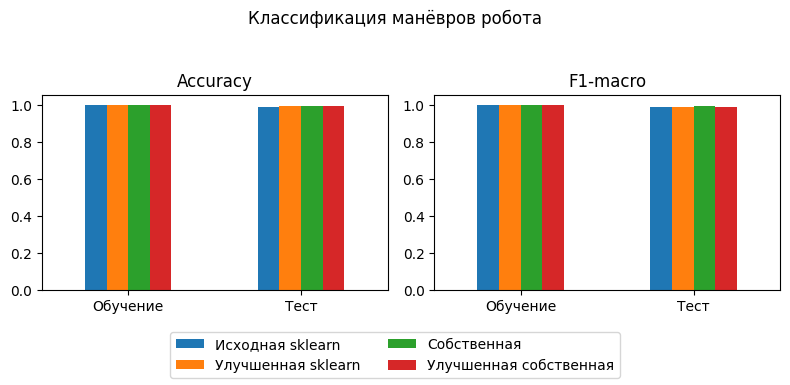

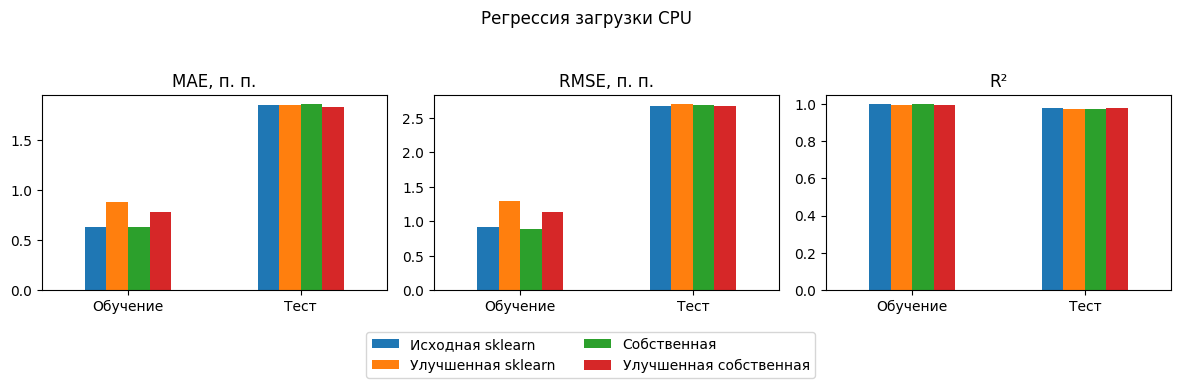

In [15]:
for title, results in [
    ("Классификация манёвров робота", final_classification),
    ("Регрессия загрузки CPU", final_regression),
]:
    fig, axes = plt.subplots(1, len(results.columns), figsize=(4 * len(results.columns), 3.8))
    for ax, metric in zip(axes, results.columns):
        scores = results[metric].unstack("Модель").reindex(columns=model_names)
        scores.plot.bar(ax=ax, rot=0, title=metric, legend=False, xlabel="")
    fig.suptitle(title)
    fig.legend(axes[0].containers, model_names, loc="lower center", ncol=2)
    fig.tight_layout(rect=(0, 0.14, 1, 0.94))
    plt.show()

### Общий вывод по лабораторной работе

- **Классификация.** У sklearn выбранные по кросс-валидации параметры повысили F1-macro на тесте с 0,9863 до 0,9885. У собственного леса перенос этих параметров снизил F1-macro с 0,9901 до 0,9888, при этом Accuracy осталась равной 0,9899.
- **Регрессия.** На тесте MAE библиотечного леса после подбора немного выросла с 1,8437 до 1,8485 п. п. У собственного леса она снизилась с 1,8521 до 1,8249 п. п., несмотря на увеличение ошибки на обучающей выборке.

Одинаковый `random_state` делает повторные вызовы собственной реализации воспроизводимыми. NumPy и sklearn могут генерировать разные bootstrap-выборки и выбирать разные признаки при одном seed. На результат также влияют порядок рассмотрения равноценных разбиений и точность вычисления порогов. Поэтому при одинаковом способе объединения прогнозов леса могут давать разные метрики.

Параметры, выбранные для sklearn на обучающих фолдах, перенесены в собственную реализацию. На отложенных данных эффект переноса оказался разным для классификации и регрессии.